First five rows of dataset:
  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  internet romantic  famrel  freetime  goout Dalc Walc health absences passed  
0       no       no       4         3      4    1    1      3        6     no  
1      yes       no       5         3      3    1    1      3        4     no  
2      yes       no       4         3      2    2    3      3       10    yes  
3      yes      yes       3         2      2    1    1      5        2    yes  
4       no       no       4         3      2    1    2      5        4    yes  

[5 r

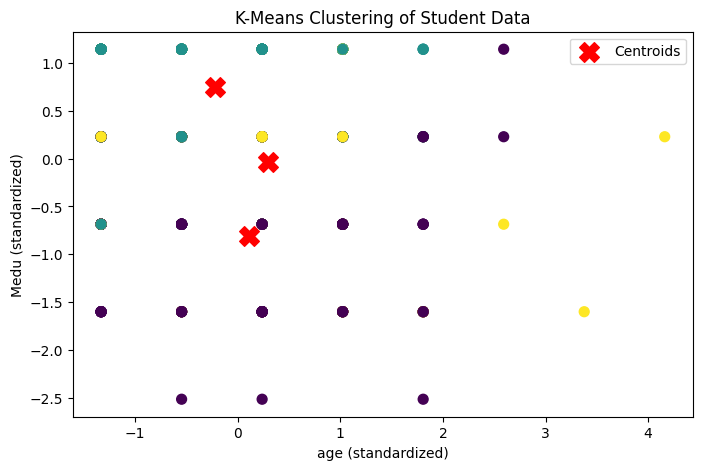


Clustered data saved to: /content/clustered_student_data.csv


In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import os
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Step 1: Load the CSV dataset
file_name = "student-data.csv"

if not os.path.exists(file_name):
    try:
        from google.colab import files
        uploaded = files.upload()
        file_name = next(iter(uploaded))
    except ImportError:
        file_name = input("Enter the full path of student-data.csv: ")

df = pd.read_csv(file_name)

print("First five rows of dataset:")
print(df.head())

# Step 2: Select numerical columns
X = df.select_dtypes(include="number")

if X.shape[1] < 2:
    raise ValueError("The CSV must contain at least two numeric columns.")

# Step 3: Handle missing values
X = X.fillna(X.median())

# Remove columns that contain no variation
X = X.loc[:, X.nunique() > 1]

if X.shape[1] < 2:
    raise ValueError("At least two varying numeric columns are required.")

# Step 4: Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 5: Apply K-Means clustering
k = 3

if len(df) < k:
    raise ValueError("The dataset must contain at least 3 rows.")

model = KMeans(n_clusters=k, random_state=42, n_init=10)
clusters = model.fit_predict(X_scaled)

# Step 6: Add cluster labels
df["Cluster"] = clusters

print("\nClustered dataset:")
print(df.head(10))

print("\nCluster counts:")
print(df["Cluster"].value_counts().sort_index())

# Step 7: Visualize the clusters
plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=clusters,
    cmap="viridis",
    s=50
)

centers = model.cluster_centers_

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    c="red",
    marker="X",
    s=200,
    label="Centroids"
)

plt.xlabel(X.columns[0] + " (standardized)")
plt.ylabel(X.columns[1] + " (standardized)")
plt.title("K-Means Clustering of Student Data")
plt.legend()
plt.show()

# Step 8: Save the clustered dataset
output_file = "clustered_student_data.csv"
df.to_csv(output_file, index=False)

print("\nClustered data saved to:", os.path.abspath(output_file))
